# Adaptive lattice displacement from a measured LEEM image

We actively reconstruct the measured512-square graphene moire image from de Jong et al.(2022). Its intensity is real observational data, with0.88nm/pixel calibration. Reference carriers are peaks measured from the same image. Thus the result is moire displacement relative to these carriers, **not an independent zero-strain or atomic-displacement calibration**.

For row/column coordinate $r$ and carrier $k$, spatial lock-in is $L_k=G_\sigma *[I(r)e^{2\pi i k\cdot r}]$. The candidate giving largest $|L|$ is selected per pixel and phase-compensated to the declared carrier. Wrapped neighbour differences $b_j$ obey $2\pi k_j\cdot\Delta u\approx b_j$; contrast weights define least squares. A weighted natural-boundary Poisson problem integrates the Cartesian displacement derivatives with a ten-step cosine-preconditioned conjugate-gradient solve. Each displacement component has zero-mean gauge. Units convert from pixels to nm only at output.

**Visual contract.** Acquisition/Fourier panels establish measured contrast and legal reference waves. Shared signed scales compare original and fresh displacement; separate difference panels expose numerical mismatch. Fixed-carrier and window-scale reconstructions test whether adaptation and spatial scale affect the inferred field. The paper's broad multi-domain/temperature/heterostrain claims are outside this bound crop; we retain the task-relevant phase/displacement comparison without implying all original figure groups were rerun.

Fresh CPU seconds: 3.7314262001309544 NCC, dynamic-range NRMSE: (1.0, 5.077061774415575e-17)


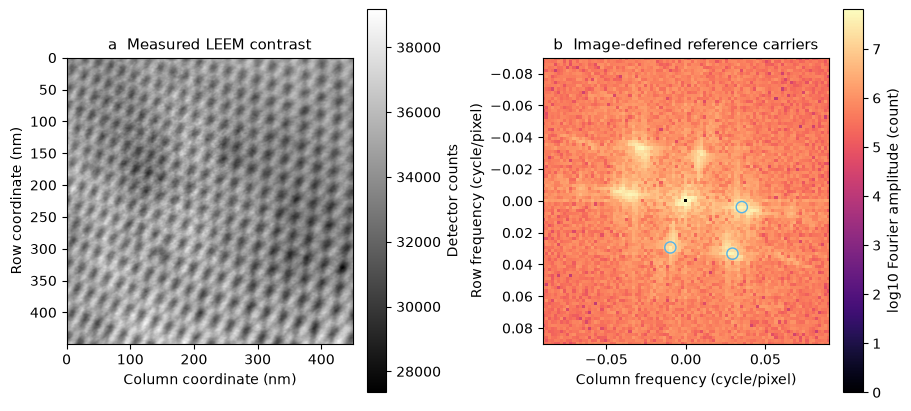

In [1]:
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0,str(root))
from src.main import run
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import acquisition_figure,comparison_figure,sensitivity_figure,agreement
plt.rcParams.update({'font.size':10,'axes.titlesize':11,'svg.fonttype':'none','pdf.fonttype':42})
data=load_data(root/'data/raw_data.npz')
t0=time.perf_counter();fresh=run(root/'data/raw_data.npz',root/'output/reconstruction.npz')[0];runtime=time.perf_counter()-t0
ref=np.load(root/'notebooks/reference_outputs/upstream.npz')['reconstruction'][0]
print('Fresh CPU seconds:',runtime,'NCC, dynamic-range NRMSE:',agreement(fresh,ref))
fig=acquisition_figure(data);plt.show()


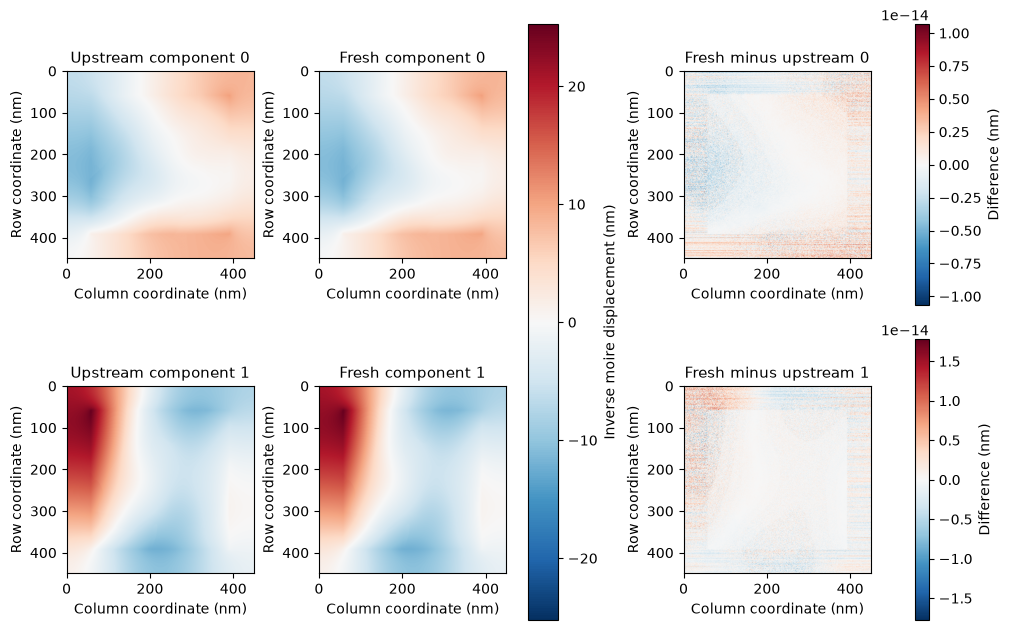

In [2]:
fig=comparison_figure(fresh,ref);plt.show()


**Independent dimensional audit.** The source integration rewraps Cartesian displacement differences as if they were phases. This is not a dimensionally general operation. On this bound image, values larger than pi occur only in the66-pixel downweighted edge:869 column-gradient and679 row-gradient entries; interior maxima are0.620618 and0.498352pixel, below pi. Removing the extra wrap in an independent integration audit changes the complete result by at most6.17e-11nm (dynamic-range NRMSE1.41e-13), and the80-pixel interior by1.68e-12nm. The edge weight is1e-6 and its squared contribution1e-12. This quantified negligible effect justifies faithful reproduction for this crop; it does not endorse the source convention for arbitrary data.

The same measured carriers and calibration are used in original and fresh runs. Differences therefore isolate extraction fidelity. A phase gauge is fixed by integration rather than optimized during evaluation. The signed maps include regions influenced by finite-image boundaries; the comparison applies to the entire declared output.

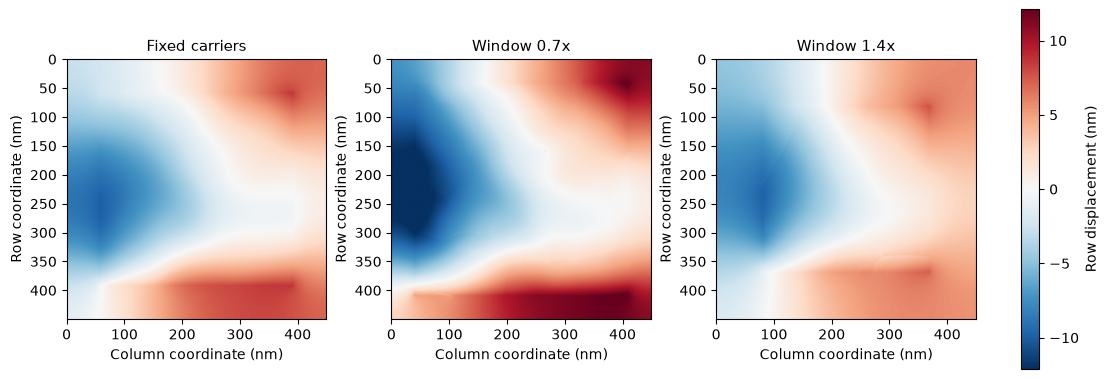

[
  {
    "method": "Fresh adaptive",
    "ncc_vs_upstream": 1.0,
    "nrmse_vs_upstream": 5.077061774415575e-17,
    "mean_u_nm": [
      0.0,
      0.0
    ],
    "interior_row_strain_rms": 0.05829583630147615
  },
  {
    "method": "Fixed carriers",
    "ncc_vs_upstream": 0.9895663633396986,
    "nrmse_vs_upstream": 0.052364679955627484,
    "mean_u_nm": [
      -5.551115123125783e-17,
      -1.1102230246251565e-16
    ],
    "interior_row_strain_rms": 0.05579972726980163
  },
  {
    "method": "Window 0.7x",
    "ncc_vs_upstream": 0.9922617162903847,
    "nrmse_vs_upstream": 0.03931373080128295,
    "mean_u_nm": [
      -2.7755575615628914e-16,
      0.0
    ],
    "interior_row_strain_rms": 0.05891651188066735
  },
  {
    "method": "Window 1.4x",
    "ncc_vs_upstream": 0.98348855657034,
    "nrmse_vs_upstream": 0.05405729266979752,
    "mean_u_nm": [
      -1.3877787807814457e-16,
      0.0
    ],
    "interior_row_strain_rms": 0.052220208323221315
  }
]


In [3]:
sigma=int(np.ceil(1/np.linalg.norm(data['reference_vectors'],axis=1).min()))
fields={'Fixed carriers':reconstruct(data,adaptive=False),'Window 0.7x':reconstruct(data,sigma=max(1,round(.7*sigma))),'Window 1.4x':reconstruct(data,sigma=round(1.4*sigma))}
fig=sensitivity_figure(fields,ref);plt.show()
rows=[]
for name,u in {'Fresh adaptive':fresh,**fields}.items():
    nc,nr=agreement(u,ref);strain=np.gradient(u[0],.88,axis=0)
    rows.append({'method':name,'ncc_vs_upstream':nc,'nrmse_vs_upstream':nr,'mean_u_nm':u.mean(axis=(1,2)).tolist(),'interior_row_strain_rms':float(np.sqrt(np.mean(strain[80:-80,80:-80]**2)))})
print(json.dumps(rows,indent=2))
np.savez_compressed(root/'notebooks/reference_outputs/fresh_measurements.npz',reconstruction=fresh[None],fixed=fields['Fixed carriers'],small_window=fields['Window 0.7x'],large_window=fields['Window 1.4x'],runtime_seconds=np.array(runtime))


In [4]:
import importlib.util
spec=importlib.util.spec_from_file_location('local_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,code=judge.evaluate(root/'output/reconstruction.npz');print(json.dumps(report,indent=2));assert code==0


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 1.0,
    "reconstruction_nrmse": 5.077061774415575e-17
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    }
  },
  "errors": []
}


Adaptive demodulation and integration reproduce the independently executed original method. Window and adaptation experiments quantify method dependence rather than error against unavailable truth. The gradients describe deformation of this observation-defined moire reference; extracting heterostrain of individual graphene sheets would require the additional model, conventions and calibration described in the source paper.